# 00 · Quickstart on synthetic data (CPU, ~1-2 min)

This notebook shows the whole HeteroSC idea without any foundation model or download:

1. four "experts" with different embedding sizes (like Geneformer 768, scGPT 512, CellFM 1536, scFoundation 768),
2. **expert-specific adapters** map them into one shared space, an **AdaptiveRouter** weights them per input,
3. the same model with the router replaced by fixed weights (**uniform fusion**, α = 1/K) as a control,
4. routing diagnostics and the zero-shot kNN probe.

> The data are synthetic. They illustrate the API and the diagnostics. They are **not** evidence about real
> foundation models: on this toy problem adaptive and uniform fusion can perform similarly. The real comparisons are in
> notebooks 03–05 and in the manuscript.

In [1]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

from heterosc import (AnnotationConfig, AnnotationTrainer, HeteroSCClassifier, make_loaders, knn_probe,
                      l2_normalize, set_seed)
from heterosc.synthetic import make_context_experts
from heterosc.plots import plot_routing_by_group

set_seed(0)
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.14.1+cu130 | cuda: False


## 1 · Synthetic experts
Each cell has a hidden *context* (think tissue). The expert that is "in-domain" for that context is clean and carries a
context signature; the other experts are noisy. A router can learn to trust the expert that shows its signature.

In [2]:
emb, y, split, context = make_context_experts(n=2000, seed=0, signal=0.35, noise_dirty=4.0, context_strength=3.0)
emb = {k: l2_normalize(v) for k, v in emb.items()}            # every expert is L2-normalised before fusion
print({k: v.shape for k, v in emb.items()})
print(pd.Series(split).value_counts().to_dict())

{'geneformer': (2000, 768), 'scgpt': (2000, 512), 'cellfm': (2000, 1536), 'scfoundation': (2000, 768)}
{'train': 1400, 'test': 300, 'val': 300}


## 2 · Train HeteroSC (adaptive routing)
Only the adapters, the router and a small classifier are trained. The "foundation models" (here: fixed arrays) never change.
The loss is class-weighted cross-entropy with label smoothing plus the **diversity regulariser** on the batch-mean routing
distribution (manuscript Eq. 6-8).

In [3]:
N_CLASSES = int(y.max()) + 1

def run(fusion):
    cfg = AnnotationConfig(
        expert_dims={k: v.shape[1] for k, v in emb.items()}, num_classes=N_CLASSES, fusion=fusion,
        d_shared=128, d_router_hidden=64, d_predictor_hidden=128,       # small for a quick CPU demo (paper: 512 / 256 / 512)
        epochs=25, warmup_epochs=3, patience=10, batch_size=64, device="cpu", seed=0)
    train, val, test = make_loaders(emb, y, split, cfg.batch_size)
    model = HeteroSCClassifier(cfg)
    result = AnnotationTrainer(model, cfg).fit(train, val, test, y[split == "train"], log_every=10)
    return cfg, model, result

cfg_a, model_a, res_a = run("adaptive")

ep   1 | lr 1.7e-04 | val F1 0.2573 acc 0.2933 | H_norm 0.993 | alpha [0.195 0.245 0.286 0.274]


ep  10 | lr 4.1e-04 | val F1 0.9903 acc 0.9900 | H_norm 0.991 | alpha [0.229 0.213 0.32  0.238]


ep  20 | lr 9.0e-05 | val F1 0.9967 acc 0.9967 | H_norm 0.995 | alpha [0.243 0.222 0.302 0.233]


early stopping at epoch 25
TEST  acc 0.9900 | macro-F1 0.9900 | alpha [0.24  0.22  0.308 0.233] | H_norm 0.994


## 3 · Control: uniform fusion
Same adapters, same head, same training, but α_k = 1/K for every input (manuscript Section 3.4).

In [4]:
cfg_u, model_u, res_u = run("uniform")

pd.DataFrame({
    "HeteroSC (adaptive)": {k: res_a["test"][k] for k in ("accuracy", "macro_f1", "normalized_entropy")},
    "Uniform fusion":      {k: res_u["test"][k] for k in ("accuracy", "macro_f1", "normalized_entropy")},
}).T.round(3)

ep   1 | lr 1.7e-04 | val F1 0.1786 acc 0.1967 | H_norm 1.000 | alpha [0.25 0.25 0.25 0.25]


ep  10 | lr 4.1e-04 | val F1 0.9670 acc 0.9667 | H_norm 1.000 | alpha [0.25 0.25 0.25 0.25]


ep  20 | lr 9.0e-05 | val F1 0.9762 acc 0.9767 | H_norm 1.000 | alpha [0.25 0.25 0.25 0.25]


TEST  acc 0.9800 | macro-F1 0.9798 | alpha [0.25 0.25 0.25 0.25] | H_norm 1.000


,accuracy,macro_f1,normalized_entropy
HeteroSC (adaptive),0.99,0.99,0.994
Uniform fusion,0.98,0.98,1.000


## 4 · What did the router learn?
Mean routing weight per expert, grouped by the hidden context of the test cells. The dashed line is the uniform weight.
`normalized_entropy` (Eq. 9) is 1 for perfectly even usage and 0 when one expert takes everything.

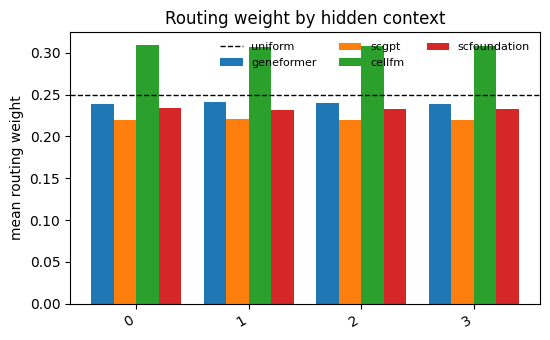

In [5]:
test_idx = np.where(split == "test")[0]
plot_routing_by_group(res_a["test"]["alphas"], context[test_idx], list(emb), title="Routing weight by hidden context")
plt.tight_layout(); plt.show()

## 5 · Zero-shot kNN in the fused space
Five nearest neighbours, cosine distance, distance-weighted voting, no trained classifier head (manuscript Section 2.3).

In [6]:
def fused(model, s):
    e = {k: torch.tensor(v[split == s]) for k, v in emb.items()}
    return model.fused_embeddings(e).cpu().numpy()

for name, m in [("adaptive", model_a), ("uniform", model_u)]:
    print(name, knn_probe(fused(m, "train"), y[split == "train"], fused(m, "test"), y[split == "test"]))

adaptive {'accuracy': 0.9866666666666667, 'macro_f1': 0.9867385820215606, 'n_neighbors': 5, 'metric': 'cosine'}
uniform {'accuracy': 0.98, 'macro_f1': 0.9795903452832353, 'n_neighbors': 5, 'metric': 'cosine'}


## Next
* `01` download the data from Zenodo, `02a–d` extract embeddings from the real foundation models,
* `03` annotation, `04` drug response, `05` gene perturbation, `06` routing analysis.